# **ЛАБОРАТОРНА РОБОТА 5**
## Кластеризація

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

## **1. Завантаження та підготовка даних**
### Посилання на набір даних [https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

In [2]:
df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Розмір датасету:", df.shape)
print("\nНазви стовпців:")
print(df.columns.tolist())

Розмір датасету: (200, 5)

Назви стовпців:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [4]:
print("Пропущені значення:")
print(df.isnull().sum())

Пропущені значення:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [5]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


In [6]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values

print("X shape:", X.shape)

X shape: (200, 2)


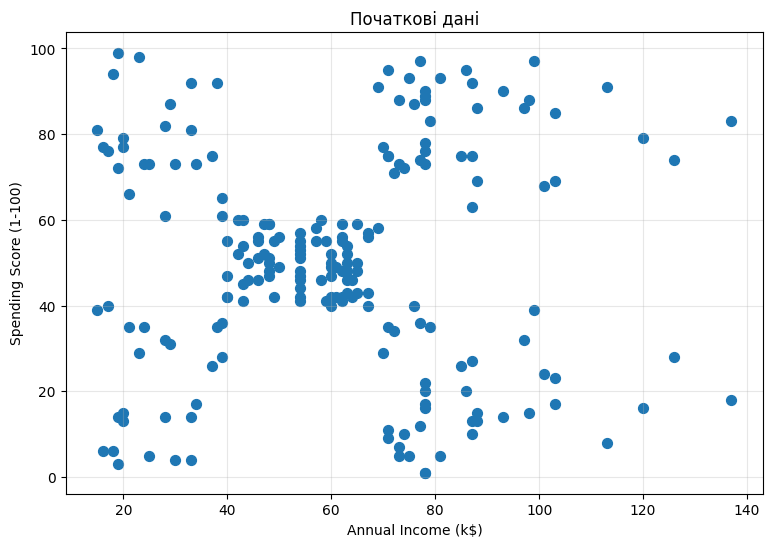

In [7]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=50
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Початкові дані")
plt.grid(alpha=0.3)

plt.show()

### Стандартезація

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Середні значення:", X_scaled.mean(axis=0))
print("Стандартні відхилення:", X_scaled.std(axis=0))

Середні значення: [-2.13162821e-16 -1.46549439e-16]
Стандартні відхилення: [1. 1.]


## **2. Власна реалізація K-Means на NumPy**

In [9]:
class MyKMeans:
    
    def __init__(self, n_clusters=3, max_iter=100, tol=1e-4, random_state=42):
        # Set model parameters
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        
        # Initialize model attributes
        self.centroids = None
        self.labels = None
        self.inertia_ = None
        self.inertia_history = []
    
    def fit(self, X):
        # Set random seed
        np.random.seed(self.random_state)
        
        # Select random initial centroids
        random_indices = np.random.choice(
            len(X),
            self.n_clusters,
            replace=False
        )
        
        self.centroids = X[random_indices].copy()
        
        # Repeat clustering steps
        for iteration in range(self.max_iter):
            
            # Calculate distances to centroids
            distances = np.sqrt(
                ((X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
            )
            
            # Assign points to the nearest centroid
            labels = np.argmin(distances, axis=1)
            
            # Calculate new centroids
            new_centroids = np.array([
                X[labels == k].mean(axis=0)
                if np.any(labels == k)
                else self.centroids[k]
                for k in range(self.n_clusters)
            ])
            
            # Calculate inertia
            inertia = np.sum(
                (X - new_centroids[labels]) ** 2
            )
            
            # Save inertia
            self.inertia_history.append(inertia)
            
            # Calculate centroid movement
            centroid_shift = np.linalg.norm(
                new_centroids - self.centroids
            )
            
            # Update centroids
            self.centroids = new_centroids
            
            # Stop if centroids change very little
            if centroid_shift < self.tol:
                break
        
        # Save final labels and inertia
        self.labels = labels
        self.inertia_ = self.inertia_history[-1]
        
        return self
    
    def predict(self, X):
        # Calculate distances to centroids
        distances = np.sqrt(
            ((X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
        )
        
        # Assign points to the nearest centroid
        return np.argmin(distances, axis=1)
    
    def fit_predict(self, X):
        # Train the model and return cluster labels
        self.fit(X)
        return self.labels

### Підбір оптимальної кількості кластерів

In [10]:
k_values = range(2, 11)
silhouette_scores = []

for k in k_values:
    
    model = MyKMeans(n_clusters=k, max_iter=100, random_state=42)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score( X_scaled, labels)
    
    silhouette_scores.append(score)

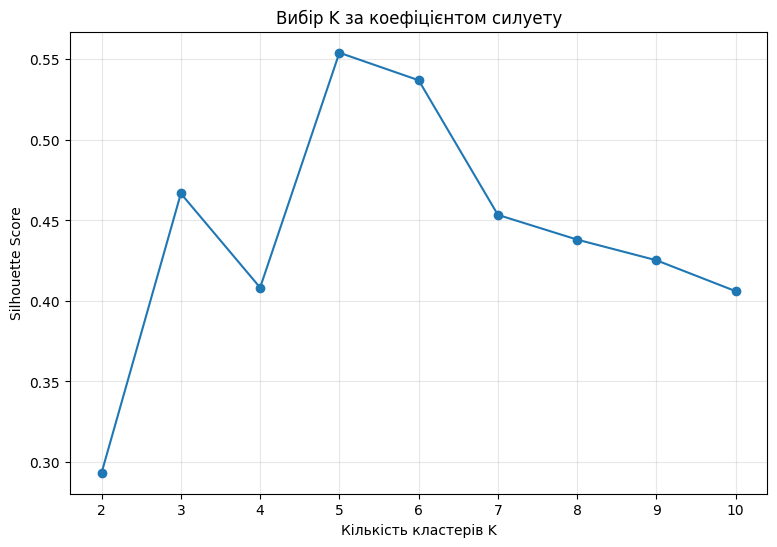

In [11]:
plt.figure(figsize=(9, 6))

plt.plot(k_values, silhouette_scores, marker="o" )

plt.xlabel("Кількість кластерів K")
plt.ylabel("Silhouette Score")
plt.title("Вибір K за коефіцієнтом силуету")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [12]:
best_k = k_values[np.argmax(silhouette_scores)]
print("Оптимальна кількість кластерів:", best_k)

Оптимальна кількість кластерів: 5


### Навчання моделі K-Means з оптимальною кількістю кластерів

In [13]:
start = time.perf_counter()
my_kmeans = MyKMeans(n_clusters = best_k, max_iter=100, random_state=42)

my_labels = my_kmeans.fit_predict(X_scaled)

my_time = time.perf_counter() - start

print("My_kmeans Silhouette:", silhouette_score(X_scaled, my_labels))

My_kmeans Silhouette: 0.5539423799434205


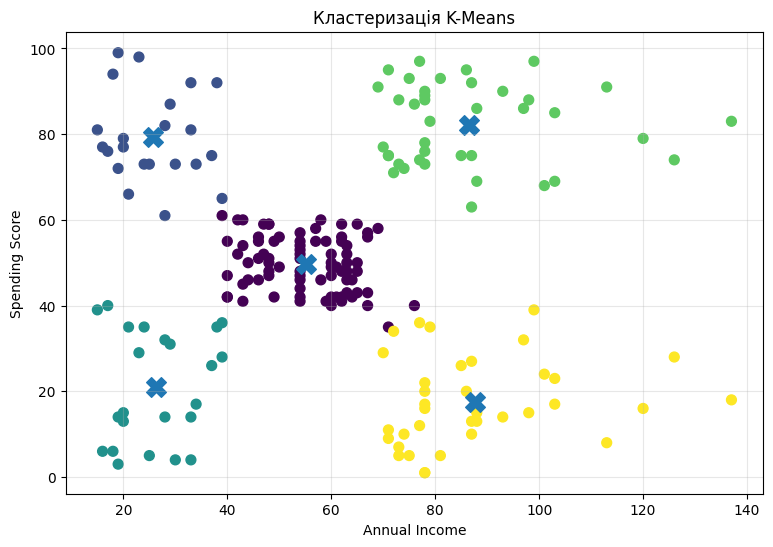

In [14]:
plt.figure(figsize=(9, 6))
plt.scatter(X[:, 0], X[:, 1], c=my_labels, s=50)

centroids_original = scaler.inverse_transform( my_kmeans.centroids)

plt.scatter(centroids_original[:, 0], centroids_original[:, 1], marker="X", s=200)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Кластеризація K-Means")
plt.grid(alpha=0.3)

plt.show()

## **3. Реалізація за допомогою Scikit-learn K-Means**

In [15]:
start = time.perf_counter()
sklearn_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

sklearn_labels = sklearn_kmeans.fit_predict(X_scaled)
sklearn_time = time.perf_counter() - start

print("Sklearn Silhouette:", silhouette_score(X_scaled, sklearn_labels))

Sklearn Silhouette: 0.5546571631111091


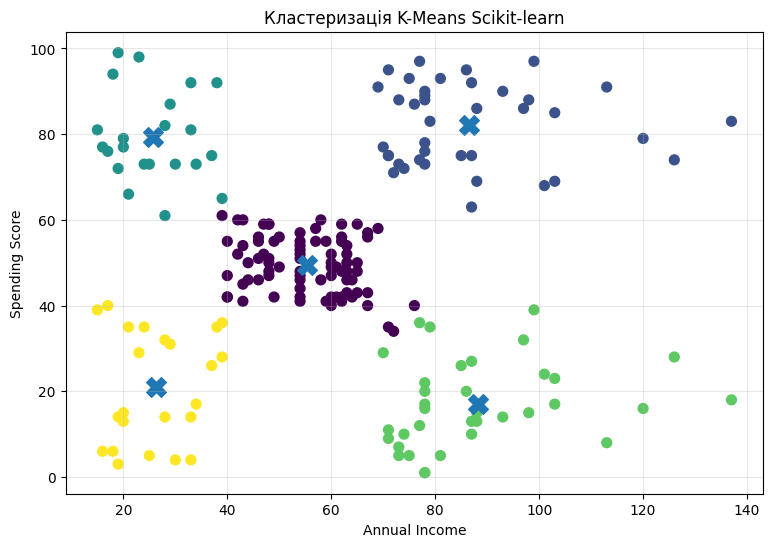

In [16]:
plt.figure(figsize=(9, 6))
plt.scatter(X[:, 0], X[:, 1], c=sklearn_labels, s=50)

centroids_original = scaler.inverse_transform( sklearn_kmeans.cluster_centers_)

plt.scatter(centroids_original[:, 0], centroids_original[:, 1], marker="X", s=200,)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Кластеризація K-Means Scikit-learn")
plt.grid(alpha=0.3)

plt.show()

## **4. Реалізація за допомогою Scikit-learn Agglomerative Clustering**

In [17]:
start = time.perf_counter()
agglomerative = AgglomerativeClustering(n_clusters=best_k)

agg_labels = agglomerative.fit_predict(X_scaled)

agg_time = time.perf_counter() - start

print("Agglomerative Silhouette:", silhouette_score(X_scaled, agg_labels))

Agglomerative Silhouette: 0.5538089226688662


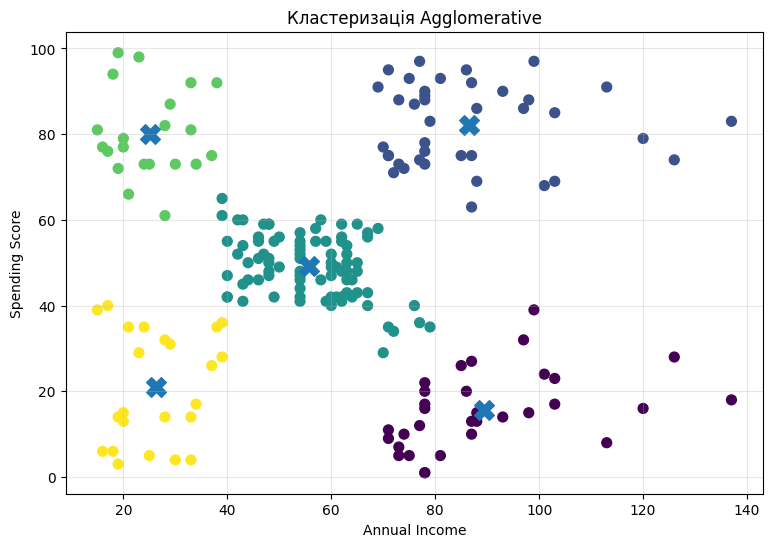

In [18]:
plt.figure(figsize=(9, 6))
plt.scatter(X[:, 0], X[:, 1], c=agg_labels, s=50)

centroids = np.array([X[agg_labels == k].mean(axis=0) for k in range(best_k)])
plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Кластеризація Agglomerative")
plt.grid(alpha=0.3)
plt.show()

## **4. Результат**

In [19]:
clustering_results = pd.DataFrame({
    "Algorithm": [
        "My K-Means",
        "Scikit-learn K-Means",
        "Agglomerative"
    ],
    "Silhouette Score": [
        silhouette_score(X_scaled, my_labels),
        silhouette_score(X_scaled, sklearn_labels),
        silhouette_score(X_scaled, agg_labels)
    ], 
    "Time, s": [
            my_time,
            sklearn_time,
            agg_time
    ]
})

clustering_results

,Algorithm,Silhouette Score,"Time, s"
0,My K-Means,0.553942,0.004084
1,Scikit-learn K-Means,0.554657,2.987626
2,Agglomerative,0.553809,0.015037
